In [122]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_spec import *
import os
from tqdm import tqdm
import json
from datetime import date
from sklearn.cluster import KMeans
import seaborn as sns

In [2]:
# Get the current date
todays_date = date.today()
year = str(todays_date.year)
if todays_date.month < 10:
    month = '0'+str(todays_date.month)
else:
    month = str(todays_date.month)

if todays_date.day < 10:
    day = '0'+str(todays_date.day)
else:
    day = str(todays_date.day)

current_date = year+month+day
directory_name = 'results/'+current_date
if not os.path.isdir(directory_name):
    os.mkdir(directory_name)
    
directory_name

'results/20251012'

In [3]:
remove_slopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="SLOPPe Remove")

mIRageLibraySpectra_Removed = pd.read_csv('../gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'

dict_slopp_reb = {'PE':'Polyethylene', 
                  'PP':'Polypropylene', 
                  'PSL':'Polystyrene'}

with open('processed_data/passive_data_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

    
ids_sat = list(saturated_wn_dict.keys())

slopp_df = pd.read_csv('processed_data/slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])

slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)
slopp_df.loc[slopp_df['polymer'] == "Polyester",'polymer'] = "Polyethylene Terephthalate"
slopp_df = slopp_df.loc[[x not in np.array(remove_slopp['Example']) for x in slopp_df['id']], :].reset_index(drop=True)

rebecca_raman_df = pd.read_csv('processed_data/rebecca_data_raman_final_specy.csv')
del rebecca_raman_df['Unnamed: 0']
rebecca_raman_df.columns = list(np.float64(rebecca_raman_df.columns[:-4])) + list(rebecca_raman_df.columns[-4:])

rebecca_raman_df = rebecca_raman_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_raman_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_raman_df = rebecca_raman_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_raman_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_raman_df['polymer']]

passive_data_raman = pd.read_csv('processed_data/passive_data_raman_specy.csv')
del passive_data_raman['Unnamed: 0']
del passive_data_raman['wn_saturated']
del passive_data_raman['id_file']
ids_no_signal = np.array(passive_data_raman.query('no_signal>0')['id'])
del passive_data_raman['no_signal']
passive_data_raman.columns = list(np.float64(passive_data_raman.columns[:-3])) + list(passive_data_raman.columns[-3:])
passive_data_raman['polymer'] = ''
passive_data_raman['label'] = ''


wn_raman = np.float64(slopp_df.columns[:-4])

min_raman_1 = 600
max_raman_1 = 1000

min_raman_2 = 1600
max_raman_2 = 3500

idx_1 = list(np.logical_or(
    np.logical_and(
        wn_raman > min_raman_1,
        wn_raman < max_raman_1),
    np.logical_and(
        wn_raman > min_raman_2,
        wn_raman < max_raman_2))) + [True]*4

min_raman_1 = 600
max_raman_1 = 910

min_raman_2 = 1040
max_raman_2 = 2310

min_raman_3 = 2500
max_raman_3 = 3500

#min_raman_1 = 600
#max_raman_1 = 1000

#min_raman_2 = 1600
#max_raman_2 = 3500

#min_raman_3 = 2500
#max_raman_3 = 3500

idx_1 = list(
    np.logical_or( 
        np.logical_or(
            np.logical_and(
                wn_raman > min_raman_1,
                wn_raman < max_raman_1),
            np.logical_and(
                wn_raman > min_raman_2,
                wn_raman < max_raman_2)
            ),   
        np.logical_and(
            wn_raman > min_raman_3,
            wn_raman < max_raman_3)
    )
    ) + [True]*4

idx_2 = idx_1[:-4] + [False]*4

slopp_df = slopp_df.loc[:,idx_1]
rebecca_raman_df = rebecca_raman_df.loc[:,idx_1]
passive_data_raman = passive_data_raman.loc[:,idx_1+[True]]
#passive_data_raman = passive_data_raman.query('id != "DC_passive_June2024_I7_20240717_90"').reset_index(drop=True)

slopp_df.iloc[:,:-4] = (slopp_df.iloc[:,:-4] - slopp_df.iloc[:,:-4].mean(1)[:,None]) / slopp_df.iloc[:,:-4].std(1)[:,None]
rebecca_raman_df.iloc[:,:-4] = (rebecca_raman_df.iloc[:,:-4] - rebecca_raman_df.iloc[:,:-4].mean(1)[:,None]) / rebecca_raman_df.iloc[:,:-4].std(1)[:,None]
passive_data_raman.iloc[:,:-5] = (passive_data_raman.iloc[:,:-5] - passive_data_raman.iloc[:,:-5].mean(1)[:,None]) / passive_data_raman.iloc[:,:-5].std(1)[:,None]

ids_no_signal = np.unique(
    np.concatenate([ids_no_signal,
    np.array(passive_data_raman.loc[passive_data_raman.iloc[:,:-5].T.std()<.01,'id'])]))

idx_raman_nan = np.unique(np.where(np.isnan(passive_data_raman.iloc[:,:-5]))[0])


In [4]:
remove_flopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="FLOPPe Remove")

flopp_df = pd.read_csv('processed_data/flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.loc[[x not in np.array(remove_flopp['Example']) for x in flopp_df['id']], :].reset_index(drop=True)

rebecca_ir_df = pd.read_csv('processed_data/rebecca_data_ir_final.csv')
del rebecca_ir_df['Unnamed: 0']
rebecca_ir_df.columns = list(np.float64(rebecca_ir_df.columns[:-4])) + list(rebecca_ir_df.columns[-4:])

rebecca_ir_df = rebecca_ir_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_ir_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_ir_df = rebecca_ir_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_ir_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_ir_df['polymer']]


passive_data_ir = pd.read_csv('processed_data/passive_data_ir.csv')
del passive_data_ir['Unnamed: 0']
background_ids = np.array(passive_data_ir.query('background == "background"')['id'])
passive_data_ir.columns = list(np.float64(passive_data_ir.columns[:-4])) + list(passive_data_ir.columns[-4:])
passive_data_ir['polymer'] = ''
passive_data_ir['label'] = ''

#passive_data_ir = passive_data_ir.query('id != "DC_passive_June2024_I7_20240717_90"').reset_index(drop=True)

flopp_df.iloc[:,:-4] = (flopp_df.iloc[:,:-4] - flopp_df.iloc[:,:-4].mean(1)[:,None]) / flopp_df.iloc[:,:-4].std(1)[:,None]
rebecca_ir_df.iloc[:,:-4] = (rebecca_ir_df.iloc[:,:-4] - rebecca_ir_df.iloc[:,:-4].mean(1)[:,None]) / rebecca_ir_df.iloc[:,:-4].std(1)[:,None]
passive_data_ir.iloc[:,:-6] = (passive_data_ir.iloc[:,:-6] - passive_data_ir.iloc[:,:-6].mean(1)[:,None]) / passive_data_ir.iloc[:,:-6].std(1)[:,None]

In [53]:
Passive_RamanOnly_Manual_LikelyMPs = pd.read_excel('evaluation_data/Passive_RamanOnly_Manual_LikelyMPs.xlsx', header=None).to_numpy().flatten()



In [54]:
passive_data_ir_paired = passive_data_ir.query('id not in @ids_sat and id not in @background_ids and id not in @ids_no_signal').reset_index(drop=True)
passive_data_ir_unpaired_ram = passive_data_ir.query('(id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_ir_unpaired_ir = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_ir_nopair = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)

passive_data_raman_paired = passive_data_raman.query('id not in @idx_raman_nan and (id not in @ids_sat and id not in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ram = passive_data_raman.query('id not in @idx_raman_nan and (id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ir = passive_data_raman.query('(id not in @idx_raman_nan or id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_nopair = passive_data_raman.query('(id not in @idx_raman_nan or id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)


In [55]:
(np.sum([x in Passive_RamanOnly_Manual_LikelyMPs for x in passive_data_raman_paired['id']]),
np.sum([x in Passive_RamanOnly_Manual_LikelyMPs for x in passive_data_raman_unpaired_ram['id']]),
np.sum([x in Passive_RamanOnly_Manual_LikelyMPs for x in passive_data_raman_unpaired_ir['id']]))

(0, 877, 0)

In [6]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.shape[0])
print('no pair spectra: ', passive_data_ir_nopair.shape[0])
print('paired spectra: ', passive_data_ir_paired.shape[0])

unpaired Raman spectra:  1824
unpaired IR spectra:  2096
no pair spectra:  193
paired spectra:  4073


In [47]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df,
                                    rebecca_raman_df,
                                    passive_data_raman_unpaired_ram)

(_, _, X_test_raman, 
 _, _, _, 
 _, _, _, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                             calibration_set_raman,
                                             test_set_raman)


(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df,
                                    rebecca_raman_df,
                                    passive_data_raman_paired)

(_, _, X_train_raman, 
 _, _, _, 
 _, _, _, 
 _, wl_list_raman) = process_data(reference_library_raman,
                                             calibration_set_raman,
                                             test_set_raman)

In [102]:
[x in Passive_RamanOnly_Manual_LikelyMPs for x in passive_data_raman_unpaired_ram['id']]

[True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 False,
 True,
 False,
 True,
 False,
 True,
 True,
 True,
 True,
 False,
 False,
 True,
 False,
 False,
 True,
 True,
 False,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 False,
 False,
 True,
 True,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 Tr

In [22]:
from sklearn.metrics import silhouette_score
from sklearn.metrics import pairwise_distances

In [39]:
list1 = []
list2 = []
for j in range(10):
    np.random.seed(j)
    inter_dist_list = []
    silhouette_score_list = []
    idx_train = np.random.rand(X_test_raman.shape[0]) > .3
    x_train_1 = X_test_raman[idx_train]
    x_cal_1 = X_test_raman[~idx_train]
    for n_cluster in np.arange(2,25,step=1):
        kmeans = KMeans(n_clusters=n_cluster, random_state=0).fit(x_train_1)
        #kmeans.labels_
        clust_km_hat = kmeans.predict(x_cal_1)
        # total within-cluster sum-of-squares
        inter_dist_list.append(np.mean([np.mean(pairwise_distances(x_cal_1)[clust_km_hat==c,:][:,clust_km_hat==c].mean(0)) for c in range(n_cluster)]))
        silhouette_score_list.append(silhouette_score(x_cal_1, clust_km_hat,))
    list1.append(inter_dist_list)
    list2.append(silhouette_score_list)
    print(j)

0
1
2
3
4
5
6
7
8
9


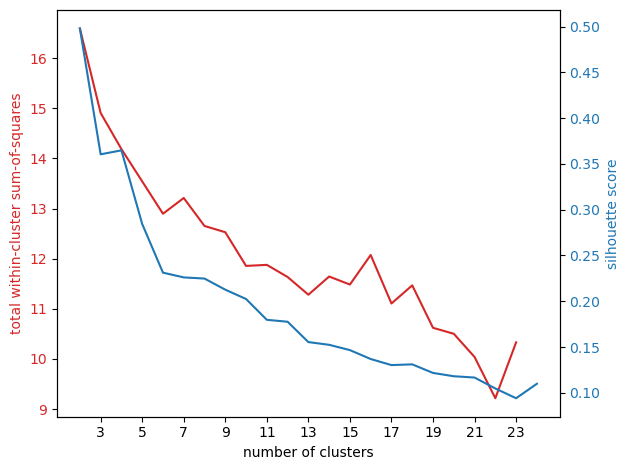

In [43]:
t = np.arange(2,25,step=1)
#plt.plot(, inter_dist_list)
#plt.plot(np.arange(4,25), np.array(silhouette_score_list)*100+10)
fig, ax1 = plt.subplots()
color = 'tab:red'
ax1.set_xlabel('number of clusters')
ax1.set_ylabel('total within-cluster sum-of-squares', color=color)
ax1.plot(t, np.nanmean(np.array(list1),0), color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(np.arange(3,25,step=2))

ax2 = ax1.twinx()  # instantiate a second Axes that shares the same x-axis

color = 'tab:blue'
ax2.set_ylabel('silhouette score', color=color)  # we already handled the x-label with ax1
ax2.plot(t, np.mean(np.array(list2),0), color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.show()

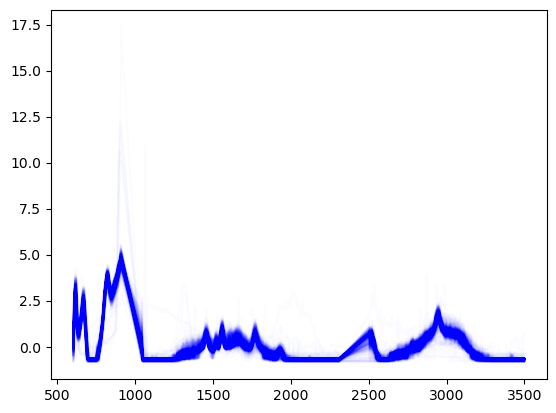

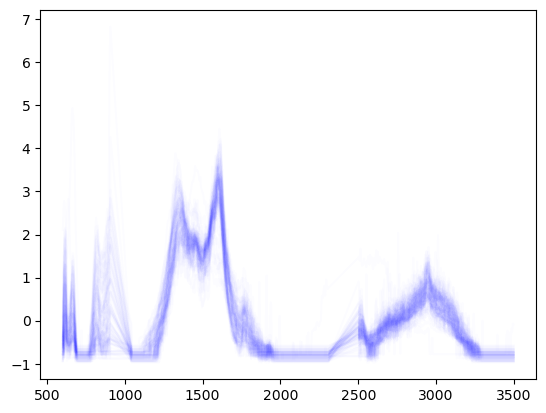

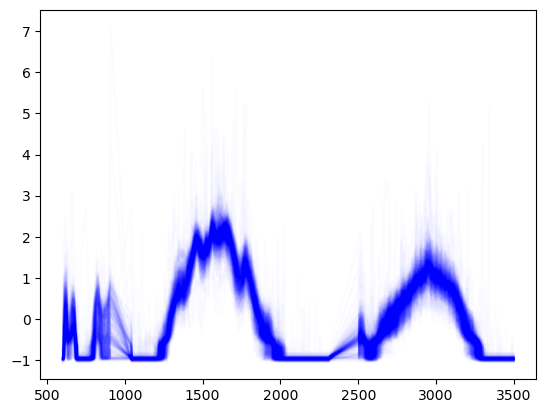

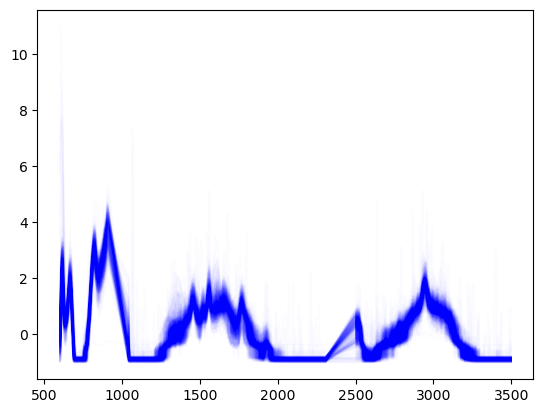

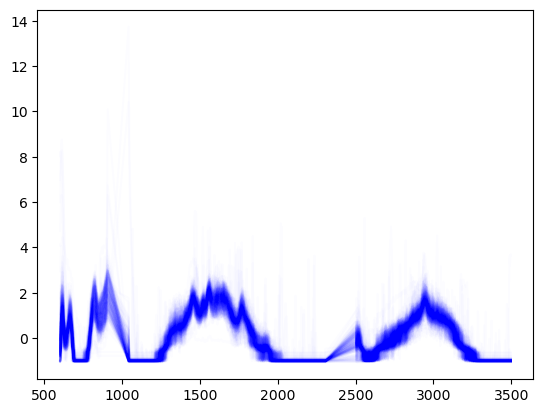

In [114]:
n_cluster = 5
kmeans = KMeans(n_clusters=n_cluster, random_state=0).fit(X_test_raman)
#kmeans.labels_
clust_km_hat = kmeans.predict(X_train_raman)
clust_km_hat_test = kmeans.predict(X_test_raman)

mean_cluster_km = []
for i in range(n_cluster):
    mean_cluster_km.append(X_train_raman[clust_km_hat == i,:].mean(0))
    #_ = plt.plot(wl_list_raman, 
    #             X_train_raman[clust_km_hat == i,:].T+5, c='b', alpha=.01)
    _ = plt.plot(wl_list_raman, 
                 X_test_raman[clust_km_hat_test == i,:].T, c='b', alpha=.01)
    _ = plt.show()

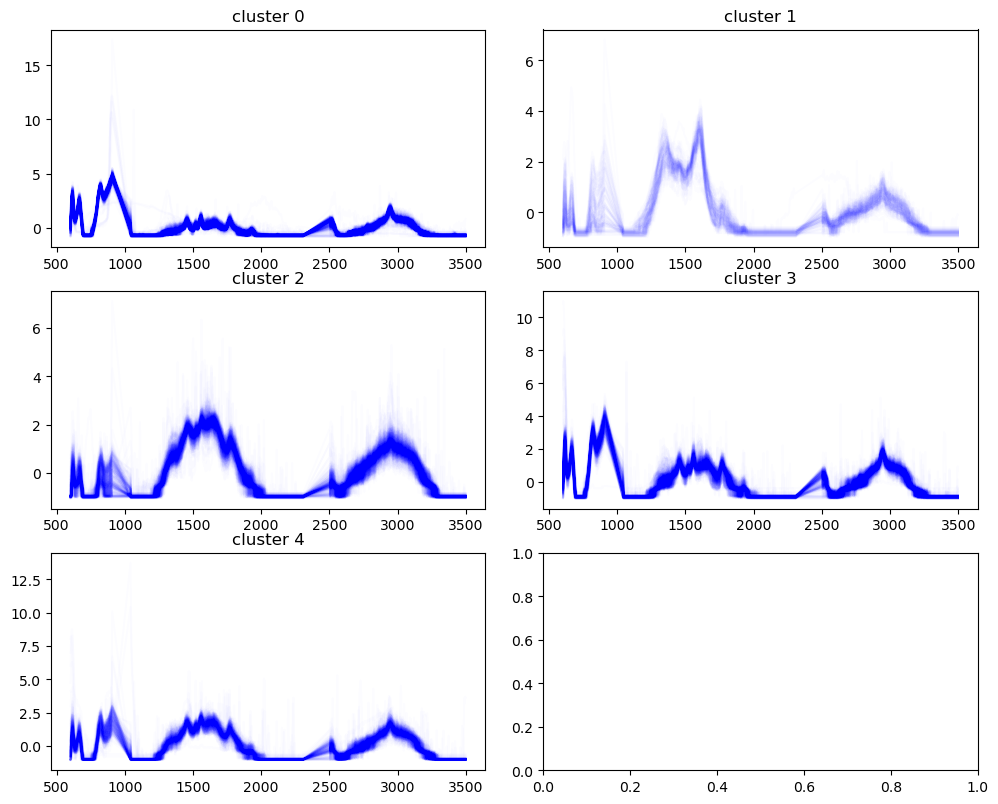

In [134]:
fig, ax = plt.subplots(nrows=3, ncols=2,figsize=(10, 8))
fig.tight_layout()

for i, row in enumerate(ax):
    for j, col in enumerate(row):
        if i * 2 + j > 4:
            break
        #mean_cluster_km.append(x[clust_km_hat == i,:].mean(0))
        #_ = col.plot(df_ir_all_norm.loc[idx_rem,:].loc[(clust_km_hat == i * 3 + j),:].T, c='b', alpha=.02)
         
        #_ = col.plot(wl_list_raman, 
        #         x[clust_km_hat == i * 2 + j,:].T+5, c='b', alpha=.01)
        _ = col.plot(wl_list_raman, 
                     X_test_raman[clust_km_hat_test == i * 2 + j,:].T, c='b', alpha=.01)
        _ = col.set_title('cluster '+str(i * 2 + j))
        #_ = plt.show()

In [124]:
res_df = pd.DataFrame({
    'n':1,
    'cluster':clust_km_hat_test,
    'LikelyMPs':[x in Passive_RamanOnly_Manual_LikelyMPs 
              for x in passive_data_raman_unpaired_ram['id']]}).groupby(['cluster', 'LikelyMPs']).count().reset_index()


conf_mat_1 = pd.pivot_table(res_df, values='n', index='cluster', columns='LikelyMPs', aggfunc=np.sum).to_numpy().T

conf_mat_2 = conf_mat_1 / conf_mat_1.sum(1)[:,None]

In [125]:
pd.pivot_table(res_df, values='n', index='cluster', columns='LikelyMPs', aggfunc=np.sum).T

cluster,0,1,2,3,4
LikelyMPs,,,,,
False,79,18,371,221,258
True,553,88,20,166,50


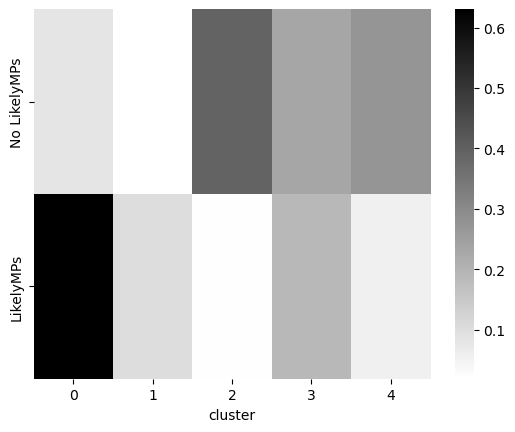

In [133]:
_ = sns.heatmap(conf_mat_2, 
                #annot=True,
                yticklabels=['No LikelyMPs', 'LikelyMPs'],
                xticklabels=np.arange(n_cluster), 
                cmap = 'binary')
_ = plt.xlabel('cluster')